# Lecture 14

In [1]:
from datascience import *
%matplotlib inline

import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np

import warnings
warnings.simplefilter("ignore")

## Data Exploration

Suppose we have a dataset containing baby birth weight in ounces, the number of gestational days, the mother’s age in completed years, the mother’s height in inches, pregnancy weight in pounds, and whether or not the mother smoked during pregnancy.

In [2]:
births = Table.read_table('baby.csv')
births.show(5)

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
128,279,28,64,115,True
108,282,23,67,125,True
136,286,25,62,93,False


In [3]:
births.select('Maternal Smoker', 
              'Birth Weight').show(5)

Maternal Smoker,Birth Weight
False,120
False,113
True,128
True,108
False,136


In [5]:
sum(births.select('Maternal Smoker', 
              'Birth Weight').column('Maternal Smoker'))

459

In [7]:
births.select('Maternal Smoker', 
              'Birth Weight').group('Maternal Smoker', np.average)

Maternal Smoker,Birth Weight average
False,123.085
True,113.819


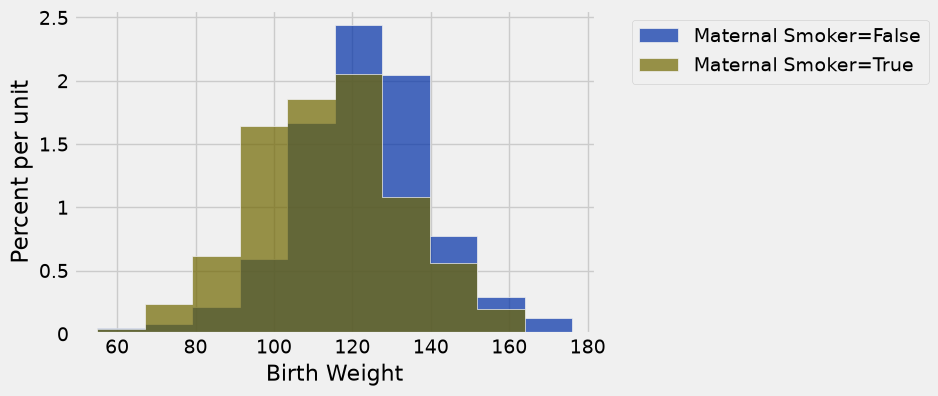

In [8]:
births.select('Maternal Smoker', 
              'Birth Weight').hist('Birth Weight', group='Maternal Smoker')

### Permutations

In [9]:
survey = Table().read_table('tardiness_survey.csv').relabeled('What percent of the time are you late to a meeting?', 'tardiness')
survey

Input a unique identifier,tardiness
1,10
2,90
3,12
4,2
5,5
6,50
7,8
8,5
9,5
10,0


In [11]:
survey.sample(5)

Input a unique identifier,tardiness
31,0
12,5
19,70
12,5
5,5


In [24]:
survey.sample(5, with_replacement=False)

Input a unique identifier,tardiness
8,5
17,0
98,99
27,65
99,50


In [27]:
survey.sample(with_replacement=False)

Input a unique identifier,tardiness
4,2
23,6
15,1
22,2
27,65
13,5
19,70
11,10
16,10
18,42


### Inference step (performing the hypothesis test)

#### How should we simulate under the null?

In [30]:
births.select('Maternal Smoker').group('Maternal Smoker')

Maternal Smoker,count
False,715
True,459


In [48]:
births.select('Maternal Smoker').sample(with_replacement = False)

Maternal Smoker
False
True
True
False
True
False
False
False
True
False


In [57]:
shuffled_group = births.select('Maternal Smoker').sample(with_replacement = False)

In [60]:
shuffled_group

Maternal Smoker
False
False
False
True
False
False
False
True
True
False


In [50]:
simulated_births = Table().with_columns('Shuffled Maternal Smoker', shuffled_group.column(0),
                                        'Birth Weight', births.column('Birth Weight'))
simulated_births.show(5)

Shuffled Maternal Smoker,Birth Weight
False,120
True,113
False,128
False,108
True,136


In [52]:
simulated_births.group('Shuffled Maternal Smoker', np.average)

Shuffled Maternal Smoker,Birth Weight average
False,119.551
True,119.325


In [55]:
avg_birth_weights = simulated_births.group('Shuffled Maternal Smoker', np.average).column(1)
avg_birth_weights

array([ 119.55104895,  119.32461874])

In [56]:
avg_birth_weights.item(1) - avg_birth_weights.item(0)

-0.2264302146655126

In [51]:
births.select('Maternal Smoker', 'Birth Weight').show(5)

Maternal Smoker,Birth Weight
False,120
False,113
True,128
True,108
False,136


In [61]:
def simulated_difference(table, group_label, numeric_label, function):
    """
    Takes: 
       - name of table
       - column label of categorical variable
       - column label of numerical variable
       - statistic to be calculated (as a function)
       
    Returns: Difference in statistics of the two groups
    """
    # We want to shuffle our labels
    shuffled_group = table.select(group_label).sample(with_replacement = False)

    # We want to make a new table with our shuffled labels and the data
    simulated_table = shuffled_group.with_column(numeric_label, table.column(numeric_label))

    # We want to compute the statistic on the shuffled data
    stats_array = simulated_table.group(group_label, function).column(1)

    # Return the difference between the two statistics
    return stats_array.item(1) - stats_array.item(0)

In [77]:
simulated_difference(births, 'Maternal Smoker', 'Birth Weight', np.average)

1.222356292944525

**Task**: 
- Simulate 2500 test statistics under the null hypothesis and save them into an array called `simulated_differences.`

In [78]:
simulated_differences = make_array()

for i in np.arange(2500):
    one_simulation = simulated_difference(births, 'Maternal Smoker', 'Birth Weight', np.average)
    simulated_differences = np.append(simulated_differences, one_simulation)

In [80]:
observed_difference = births.group('Maternal Smoker', np.average).column(1).item(1) - births.group('Maternal Smoker', np.average).column(1).item(0)

In [81]:
observed_difference

-9.266142572024918

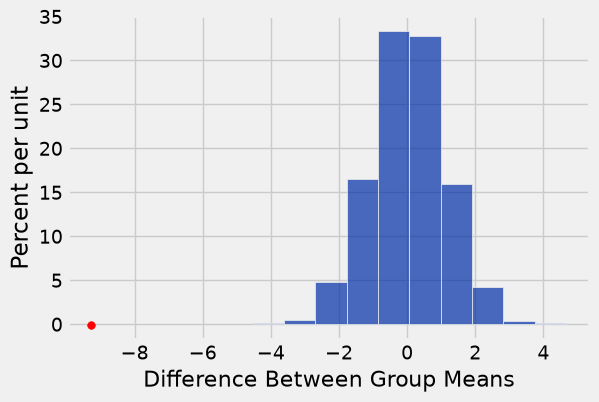

In [82]:
differences_tbl = Table().with_column('Difference Between Group Means', 
                    simulated_differences)
differences_tbl.hist()
plots.scatter(observed_difference, -0.001, color='red', s=30);

In [87]:
sum(simulated_differences <= -2) / 2500

0.0332

**Task:** If we choose a p-value cutoff of $0.05$ (5%), what is the value of our cutoff? 

- How many simulations did we do? 
- We want to find a point that contains 5% of these values. How many values are 5% of our total simulations?
- Suppose we sorted our simulations. What is the index of the item where 5% of the values are towards the alternative?

In [ ]:
five_percent_point = ...

In [ ]:
differences_tbl.hist()
plots.scatter(observed_difference, -0.001, color='red', s=30);
plots.plot([five_percent_point, five_percent_point], [0, 0.35], color='gold', lw=2);